In [1]:
import numpy as np
import pandas as pd
import ast
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
movies = pd.read_csv('tmdb_5000_movies.csv.zip')
credits = pd.read_csv('tmdb_5000_credits.csv.zip')

In [3]:
credits.head()

,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,49026,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,49529,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."


In [4]:
movies.head(1)

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800


In [5]:
print(type(movies))

<class 'pandas.core.frame.DataFrame'>


In [6]:
#merge both the datasets in one
# skip the rename entirely, merge directly
movies = movies.merge(credits, on='title')

In [7]:
movies.head()

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,...,runtime,spoken_languages,status,tagline,title,vote_average,vote_count,movie_id,cast,crew
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...",...,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800,19995,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...",...,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,285,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...",...,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466,206647,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...",...,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106,49026,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]",...,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124,49529,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."


In [8]:
movies.columns

Index(['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language',
       'original_title', 'overview', 'popularity', 'production_companies',
       'production_countries', 'release_date', 'revenue', 'runtime',
       'spoken_languages', 'status', 'tagline', 'title', 'vote_average',
       'vote_count', 'movie_id', 'cast', 'crew'],
      dtype='object')

In [9]:
movies.head()

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,...,runtime,spoken_languages,status,tagline,title,vote_average,vote_count,movie_id,cast,crew
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...",...,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800,19995,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...",...,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,285,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...",...,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466,206647,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...",...,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106,49026,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]",...,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124,49529,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."


In [10]:
movies.isnull().sum()

budget                     0
genres                     0
homepage                3096
id                         0
keywords                   0
original_language          0
original_title             0
overview                   3
popularity                 0
production_companies       0
production_countries       0
release_date               1
revenue                    0
runtime                    2
spoken_languages           0
status                     0
tagline                  844
title                      0
vote_average               0
vote_count                 0
movie_id                   0
cast                       0
crew                       0
dtype: int64

In [11]:
movies.dropna(inplace=True)

In [12]:
movies.isnull().sum()

budget                  0
genres                  0
homepage                0
id                      0
keywords                0
original_language       0
original_title          0
overview                0
popularity              0
production_companies    0
production_countries    0
release_date            0
revenue                 0
runtime                 0
spoken_languages        0
status                  0
tagline                 0
title                   0
vote_average            0
vote_count              0
movie_id                0
cast                    0
crew                    0
dtype: int64

In [13]:
movies.duplicated().sum()

np.int64(0)

In [14]:
movies.describe

<bound method NDFrame.describe of          budget                                             genres  \
0     237000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
1     300000000  [{"id": 12, "name": "Adventure"}, {"id": 14, "...   
2     245000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
3     250000000  [{"id": 28, "name": "Action"}, {"id": 80, "nam...   
4     260000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
...         ...                                                ...   
4779      27000                     [{"id": 35, "name": "Comedy"}]   
4787      22000  [{"id": 35, "name": "Comedy"}, {"id": 10749, "...   
4797         13                     [{"id": 27, "name": "Horror"}]   
4802       7000  [{"id": 878, "name": "Science Fiction"}, {"id"...   
4807          0                                                 []   

                                          homepage      id  \
0                      http://www.avatarmovie.com/   19995   
1

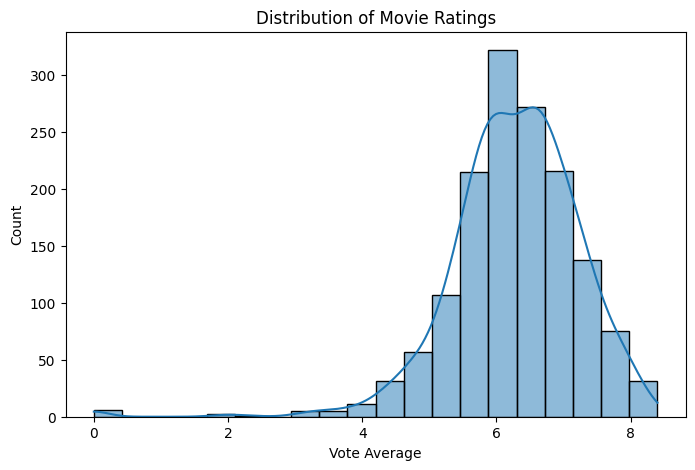

In [15]:
plt.figure(figsize=(8,5))

sns.histplot(movies['vote_average'], bins=20, kde=True)

plt.title("Distribution of Movie Ratings")

plt.xlabel("Vote Average")

plt.ylabel("Count")

plt.show()

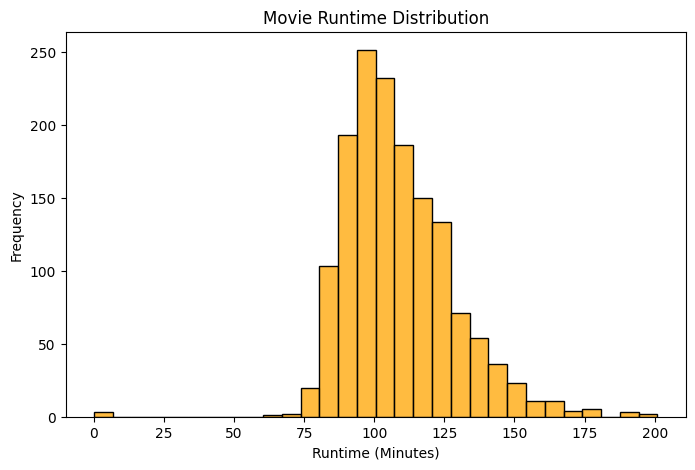

In [16]:
plt.figure(figsize=(8,5))

sns.histplot(movies['runtime'], bins=30, color='orange')

plt.title("Movie Runtime Distribution")

plt.xlabel("Runtime (Minutes)")

plt.ylabel("Frequency")

plt.show()

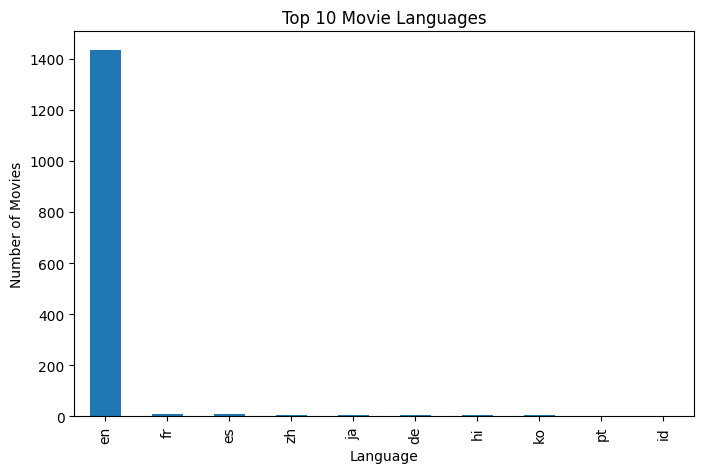

In [17]:
plt.figure(figsize=(8,5))

movies['original_language'].value_counts().head(10).plot(kind='bar')

plt.title("Top 10 Movie Languages")

plt.xlabel("Language")

plt.ylabel("Number of Movies")

plt.show()

In [18]:
movies['production_companies'].head()

0    [{"name": "Ingenious Film Partners", "id": 289...
1    [{"name": "Walt Disney Pictures", "id": 2}, {"...
2    [{"name": "Columbia Pictures", "id": 5}, {"nam...
3    [{"name": "Legendary Pictures", "id": 923}, {"...
4          [{"name": "Walt Disney Pictures", "id": 2}]
Name: production_companies, dtype: object

In [19]:
import ast

company=[]

for i in movies['production_companies']:
    try:
        company.append(ast.literal_eval(i)[0]['name'])
    except:
        company.append(np.nan)

movies['company']=company

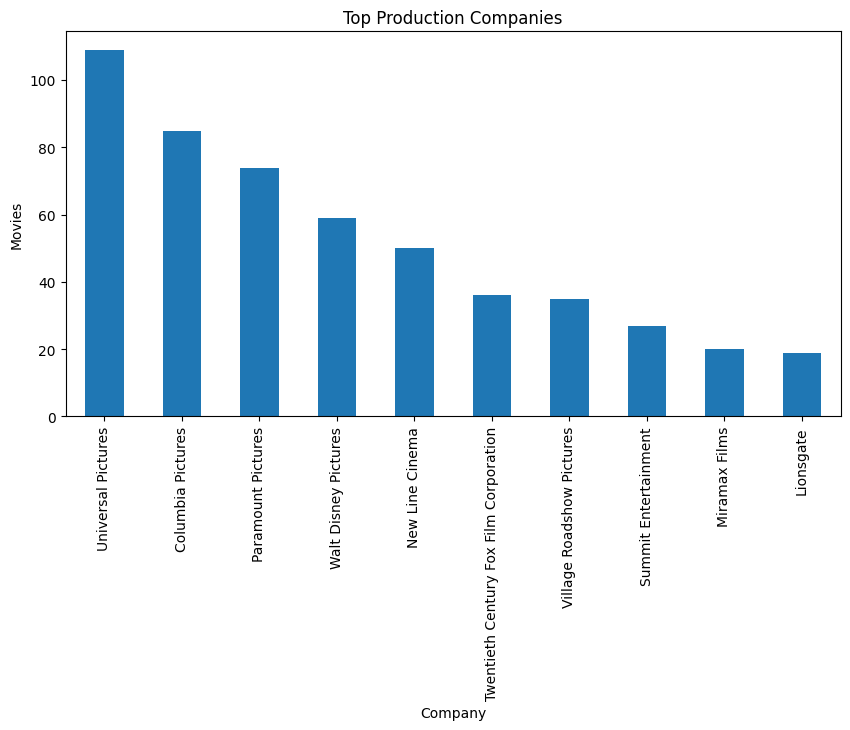

In [20]:
plt.figure(figsize=(10,5))

movies['company'].value_counts().head(10).plot(kind='bar')

plt.title("Top Production Companies")

plt.xlabel("Company")

plt.ylabel("Movies")

plt.show()

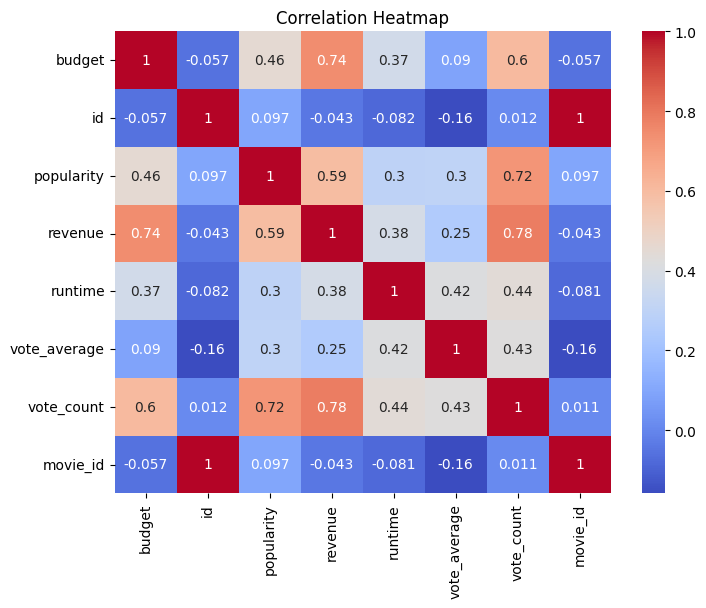

In [21]:
plt.figure(figsize=(8,6))

sns.heatmap(
    movies.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()

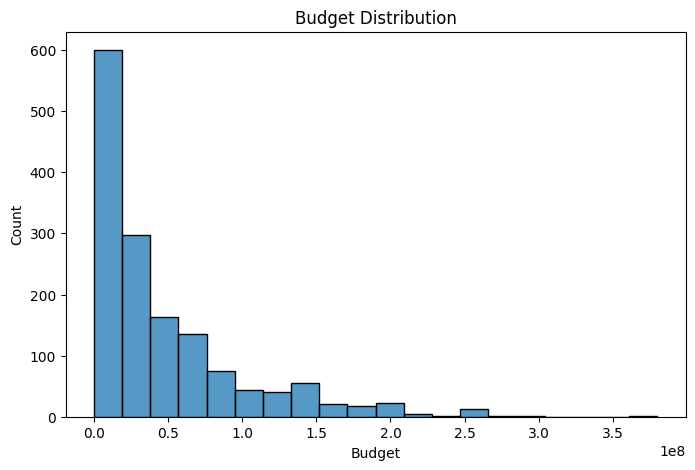

In [22]:
plt.figure(figsize=(8,5))

sns.histplot(movies['budget'], bins=20)

plt.title("Budget Distribution")

plt.xlabel("Budget")

plt.show()

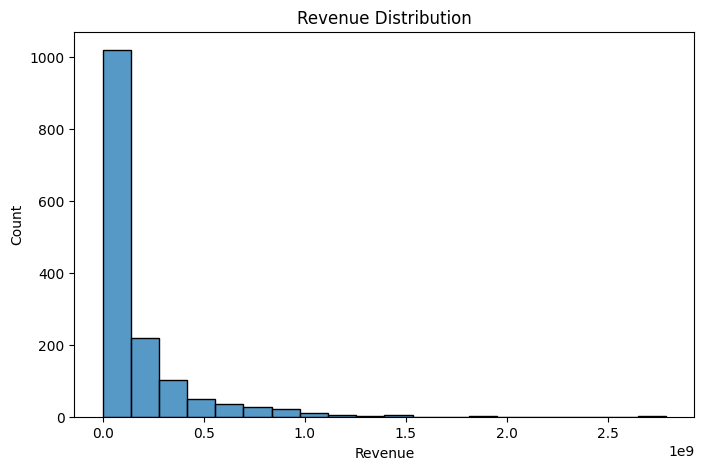

In [23]:
plt.figure(figsize=(8,5))

sns.histplot(movies['revenue'], bins=20)

plt.title("Revenue Distribution")

plt.xlabel("Revenue")

plt.show()

In [24]:
top_movies = movies[['title','vote_average']].sort_values(
    by='vote_average',
    ascending=False
).head(10)

In [32]:
movies = movies.merge(credits,on='title')

In [26]:
def convert(obj):
    L = []
    for i in ast.literal_eval(obj):
        L.append(i['name'])
    return L

In [27]:
movies['genres']=movies['genres'].apply(convert)

In [28]:
movies['genres']

0       [Action, Adventure, Fantasy, Science Fiction]
1                        [Adventure, Fantasy, Action]
2                          [Action, Adventure, Crime]
3                    [Action, Crime, Drama, Thriller]
4                [Action, Adventure, Science Fiction]
                            ...                      
1491                                         [Comedy]
1492                                [Comedy, Romance]
1493                                         [Horror]
1494               [Science Fiction, Drama, Thriller]
1495                                               []
Name: genres, Length: 1496, dtype: object

In [29]:
movies['keywords_list'] = movies['keywords'].apply(convert)

In [30]:
movies['keywords_list']

0       [culture clash, future, space war, space colon...
1       [ocean, drug abuse, exotic island, east india ...
2       [spy, based on novel, secret agent, sequel, mi...
3       [dc comics, crime fighter, terrorist, secret i...
4       [based on novel, mars, medallion, space travel...
                              ...                        
1491             [salesclerk, loser, aftercreditsstinger]
1492    [dating, divorce, sex scene, sex comedy, anti ...
1493                                      [home invasion]
1494    [distrust, garage, identity crisis, time trave...
1495                                                   []
Name: keywords_list, Length: 1496, dtype: object

In [33]:
movies['cast']=movies['cast'].apply(lambda x:[i['name'] for i in ast.literal_eval(x)[:3]])

In [34]:
movies['cast'][0]

['Sam Worthington', 'Zoe Saldana', 'Sigourney Weaver']

In [35]:
movies['crew']=movies['crew'].apply(lambda x:[i['name'] for i in ast.literal_eval(x) if i['job']=='Director'])

In [36]:
movies['crew']

0           [James Cameron]
1          [Gore Verbinski]
2              [Sam Mendes]
3       [Christopher Nolan]
4          [Andrew Stanton]
               ...         
1495          [Kevin Smith]
1496         [Travis Legge]
1497        [Ivan Kavanagh]
1498        [Shane Carruth]
1499          [Daniel Hsia]
Name: crew, Length: 1500, dtype: object

In [37]:
movies['genres']=movies['genres'].apply(lambda x:[i.replace(" ","") for i in x])

movies['keywords']=movies['keywords'].apply(lambda x:[i.replace(" ","") for i in x])

movies['cast']=movies['cast'].apply(lambda x:[i.replace(" ","") for i in x])

movies['crew']=movies['crew'].apply(lambda x:[i.replace(" ","") for i in x])

In [38]:
movies['tags']=movies['genres']+movies['crew']+movies['cast']+movies['keywords_list']

In [39]:
movies['tags']

0       [Action, Adventure, Fantasy, ScienceFiction, J...
1       [Adventure, Fantasy, Action, GoreVerbinski, Jo...
2       [Action, Adventure, Crime, SamMendes, DanielCr...
3       [Action, Crime, Drama, Thriller, ChristopherNo...
4       [Action, Adventure, ScienceFiction, AndrewStan...
                              ...                        
1495    [Comedy, KevinSmith, BrianO'Halloran, JeffAnde...
1496    [Comedy, Romance, TravisLegge, SuziLorraine, J...
1497    [Horror, IvanKavanagh, MichaelParle, EmmaEliza...
1498    [ScienceFiction, Drama, Thriller, ShaneCarruth...
1499    [DanielHsia, DanielHenney, ElizaCoupe, BillPax...
Name: tags, Length: 1500, dtype: object

In [40]:
movies['tags']=movies['tags'].apply(lambda x: " ".join(x))

In [41]:
movies['tags']

0       Action Adventure Fantasy ScienceFiction JamesC...
1       Adventure Fantasy Action GoreVerbinski JohnnyD...
2       Action Adventure Crime SamMendes DanielCraig C...
3       Action Crime Drama Thriller ChristopherNolan C...
4       Action Adventure ScienceFiction AndrewStanton ...
                              ...                        
1495    Comedy KevinSmith BrianO'Halloran JeffAnderson...
1496    Comedy Romance TravisLegge SuziLorraine JaredD...
1497    Horror IvanKavanagh MichaelParle EmmaElizaRega...
1498    ScienceFiction Drama Thriller ShaneCarruth Sha...
1499        DanielHsia DanielHenney ElizaCoupe BillPaxton
Name: tags, Length: 1500, dtype: object

In [42]:
movies['tags']=movies['tags'].apply(lambda x:x.lower())

In [43]:
movies['tags']

0       action adventure fantasy sciencefiction jamesc...
1       adventure fantasy action goreverbinski johnnyd...
2       action adventure crime sammendes danielcraig c...
3       action crime drama thriller christophernolan c...
4       action adventure sciencefiction andrewstanton ...
                              ...                        
1495    comedy kevinsmith briano'halloran jeffanderson...
1496    comedy romance travislegge suzilorraine jaredd...
1497    horror ivankavanagh michaelparle emmaelizarega...
1498    sciencefiction drama thriller shanecarruth sha...
1499        danielhsia danielhenney elizacoupe billpaxton
Name: tags, Length: 1500, dtype: object

In [44]:
genre_counts = Counter(g for row in movies['genres'] for g in row)
print("Top genres:", genre_counts.most_common(10))
 
keyword_counts = Counter(k for row in movies['keywords_list'] for k in row)
print("Top keywords:", keyword_counts.most_common(10))
 

Top genres: [('Drama', 635), ('Comedy', 500), ('Thriller', 419), ('Action', 417), ('Adventure', 323), ('Romance', 233), ('ScienceFiction', 220), ('Crime', 207), ('Family', 201), ('Fantasy', 175)]
Top keywords: [('duringcreditsstinger', 195), ('aftercreditsstinger', 98), ('woman director', 95), ('based on novel', 93), ('dystopia', 75), ('3d', 72), ('violence', 65), ('murder', 59), ('independent film', 53), ('sequel', 50)]


In [45]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf=TfidfVectorizer(stop_words='english')
tfidf_matrix=tfidf.fit_transform(movies['tags'])

In [46]:
from sklearn.metrics.pairwise import cosine_similarity
cosine_sim=cosine_similarity(tfidf_matrix,tfidf_matrix)

In [47]:
cosine_sim

array([[1.        , 0.02913113, 0.01333368, ..., 0.        , 0.03102699,
        0.        ],
       [0.02913113, 1.        , 0.01618467, ..., 0.        , 0.        ,
        0.        ],
       [0.01333368, 0.01618467, 1.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 1.        , 0.        ,
        0.        ],
       [0.03102699, 0.        , 0.        , ..., 0.        , 1.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        1.        ]])

In [48]:
def get_recommendations(title, cosine_sim=cosine_sim):
    # Remove spaces and convert to lowercase
    search = title.lower().replace(" ", "")

    matches = movies[
        movies["title"]
        .str.lower()
        .str.replace(" ", "", regex=False)
        .str.contains(search, na=False)
    ]

    if matches.empty:
        return f"Movie '{title}' not found."

    idx = matches.index[0]

    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

    sim_scores = sim_scores[1:6]

    movie_indices = [i[0] for i in sim_scores]

    return movies["title"].iloc[movie_indices]
                    

In [49]:
get_recommendations("Harry Potter")

89     Harry Potter and the Order of the Phoenix
90           Harry Potter and the Goblet of Fire
144     Harry Potter and the Philosopher's Stone
482               Hansel & Gretel: Witch Hunters
224                                  Seventh Son
Name: title, dtype: object

In [50]:
movies[movies['title'].str.contains("Harry", case=False, na=False)]

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,...,crew_x,company,movie_id_y,cast_y,crew_y,keywords_list,movie_id,cast,crew,tags
8,250000000,"[Adventure, Fantasy, Family]",http://harrypotter.warnerbros.com/harrypottera...,767,"[[, {, "", i, d, "", :, , 6, 1, 6, ,, , "", n, a,...",en,Harry Potter and the Half-Blood Prince,"As Harry begins his sixth year at Hogwarts, he...",98.885637,"[{""name"": ""Warner Bros."", ""id"": 6194}, {""name""...",...,"[{""credit_id"": ""52fe4273c3a36847f801fab1"", ""de...",Warner Bros.,767,"[{""cast_id"": 3, ""character"": ""Harry Potter"", ""...","[{""credit_id"": ""52fe4273c3a36847f801fab1"", ""de...","[witch, magic, broom, school of witchcraft, wi...",767,"[DanielRadcliffe, RupertGrint, EmmaWatson]",[DavidYates],adventure fantasy family davidyates danielradc...
89,150000000,"[Adventure, Fantasy, Family, Mystery]",http://www.harrypotterorderofthephoenix.com/,675,"[[, {, "", i, d, "", :, , 5, 3, 0, ,, , "", n, a,...",en,Harry Potter and the Order of the Phoenix,Returning for his fifth year of study at Hogwa...,78.144395,"[{""name"": ""Warner Bros."", ""id"": 6194}, {""name""...",...,"[{""credit_id"": ""52fe4268c3a36847f801c489"", ""de...",Warner Bros.,675,"[{""cast_id"": 22, ""character"": ""Harry Potter"", ...","[{""credit_id"": ""52fe4268c3a36847f801c489"", ""de...","[prophecy, witch, loss of lover, magic, cuttin...",675,"[DanielRadcliffe, RupertGrint, EmmaWatson]",[DavidYates],adventure fantasy family mystery davidyates da...
90,150000000,"[Adventure, Fantasy, Family]",http://harrypotter.warnerbros.com/,674,"[[, {, "", i, d, "", :, , 2, 3, 4, 3, ,, , "", n,...",en,Harry Potter and the Goblet of Fire,"Harry starts his fourth year at Hogwarts, comp...",101.250416,"[{""name"": ""Patalex IV Productions Limited"", ""i...",...,"[{""credit_id"": ""52fe4268c3a36847f801c275"", ""de...",Patalex IV Productions Limited,674,"[{""cast_id"": 1, ""character"": ""Harry Potter"", ""...","[{""credit_id"": ""52fe4268c3a36847f801c275"", ""de...","[magic, dying and death, broom, sorcerer's app...",674,"[DanielRadcliffe, RupertGrint, EmmaWatson]",[MikeNewell],adventure fantasy family mikenewell danielradc...
144,125000000,"[Adventure, Fantasy, Family]",http://harrypotter.warnerbros.com/harrypottera...,671,"[[, {, "", i, d, "", :, , 6, 1, 6, ,, , "", n, a,...",en,Harry Potter and the Philosopher's Stone,Harry Potter has lived under the stairs at his...,109.984351,"[{""name"": ""1492 Pictures"", ""id"": 436}, {""name""...",...,"[{""credit_id"": ""52fe4267c3a36847f801be1d"", ""de...",1492 Pictures,671,"[{""cast_id"": 27, ""character"": ""Harry Potter"", ...","[{""credit_id"": ""52fe4267c3a36847f801be1d"", ""de...","[witch, christmas party, magic, cutting the co...",671,"[DanielRadcliffe, RupertGrint, EmmaWatson]",[ChrisColumbus],adventure fantasy family chriscolumbus danielr...


In [51]:
import pickle


pickle.dump(cosine_sim, open("similarity.pkl", "wb"))

with open ('movies.pickle','wb') as file:
    pickle.dump((movies,cosine_sim),file)

In [52]:
import pickle

# Save movies dataframe
pickle.dump(movies, open("../movies.pickle", "wb"))

# Save cosine similarity matrix
pickle.dump(cosine_sim, open("../similarity.pkl", "wb"))

In [53]:
import pickle

movies = pickle.load(open("../movies.pickle", "rb"))
similarity = pickle.load(open("../similarity.pkl", "rb"))

print(type(movies))
print(type(similarity))

<class 'pandas.core.frame.DataFrame'>
<class 'numpy.ndarray'>
